In [ ]:
from pathlib import Path

import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

months = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]
months_en = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]
years = ["2013", "2014", "2015", "2016", "2017"]
spend = [
    ("Housing", 34),
    ("Food", 15),
    ("Transport", 13),
    ("Savings", 10),
    ("Utilities", 8),
    ("Health", 7),
    ("Leisure", 7),
    ("Other", 6),
]
mobile = [40, 46, 52, 58, 65, 72, 79, 86, 94, 102, 110, 120]
desktop = [61, 59, 62, 60, 58, 61, 60, 62, 59, 61, 60, 59]
delivery_days = [
    1.2, 5.7, 4.3, 5.6, 5.3, 1.6, 0.9, 0.7, 4.1, 5.5, 5.1, 6.3, 4.3, 1.4, 5.7, 6.1,
    0.9, 1.5, 4.4, 5, 1.3, 1.2, 4.2, 5.3, 1.2, 5.6, 0.7, 4.9, 0.9, 4.9, 1.1, 6.2, 2.1,
    4.4, 5.9, 0.3, 1.5, 1.6, 4.5, 4.4, 1.6, 1.4, 1.5, 4.2, 4.8, 1.7, 5, 1.6, 5, 4.9,
    1.1, 1.6, 0.8, 5.5, 1.2, 1, 1.7, 6, 1.3, 4.9, 1, 1.3, 1.4, 1.1, 1.8, 3.6, 6, 1.4,
    1.4, 5.2, 6, 1, 5.3, 4.3, 4.6, 0.5, 1.2, 4.5, 1.5, 4.6, 1.2, 1, 5.7, 1.4, 1.2, 1.8,
    1.6, 0.8, 6.7, 6.9, 1.4, 6.2, 3.4, 4.6, 0.7, 4.4, 5.5, 3.8, 1.4, 5, 1.3, 5.6, 4.6,
    1.2, 0.9, 1.6, 1.1, 5.7, 3.7, 5.4, 0.7, 4.4, 5.2, 1.1, 5.3, 3.2, 4.5, 1.4, 5.8,
    5.2, 5.5, 1.3, 5.2, 5.6, 1.4, 1.3, 1.8, 1.4, 1.1, 1.7, 6, 1.1, 5, 1.1, 1.3, 5.4,
    0.9, 1.5, 1.5, 4.9, 1, 3.6, 1.7, 1, 5.3, 0.5, 1.6, 4.4, 3.4, 5.2, 1.1, 1.5, 4.8, 4,
    1.3, 5.3, 6, 4.8, 1.2, 1.3, 0.7, 1.1, 1.3, 5.5, 5.1, 1.3, 1.7, 1.2, 1.2, 4.2, 5.1,
    4.6, 5.3, 0.8, 5.2, 1.2, 5.7, 4.6, 1.5, 1, 5.1, 0.6, 1.7, 1.5, 3.7, 4.6, 4.9, 4.5,
    4.4, 0.6, 1.6, 0.9, 5, 1.1, 1.1, 5.4, 5.7, 6.5, 3.9, 0.7, 5.5, 4.7, 5.3, 1.4, 1,
    5.4, 0.7, 1.5, 1.6, 5, 4.9, 1.5, 1.6, 5.7, 1.4, 4.7, 5.3, 0.9, 4.2, 1.3, 4.3, 5.6,
    0.7, 5.3, 1.5, 6.1, 6.3, 5.9, 0.8, 4.4, 1, 5.5, 1.5, 0.5, 5.1, 1.4, 5.1, 4.9, 5.8,
    5.7, 5, 5.5, 5.2, 6.3, 1.1, 6.4, 1.1, 4.9, 6.1, 1, 3.2, 5.4, 0.9, 1.4, 5.9, 4.9, 1,
    4.4, 1.4, 4.9, 5.1, 5.6, 1.3, 1, 4.8, 5.1, 1.4, 4.9, 3.6, 0.9, 3.7, 1.6, 5.4, 4,
    4.5, 1.4, 0.9, 3.3, 1.4, 5.3, 1.3, 5.6, 1.6, 4.5, 4.9, 5.7, 1.6, 1.1, 0.9, 5.9, 1,
    1.3, 6, 1.2, 5.6, 1.1, 5.6, 3.5, 1.3, 5.6, 5, 4.1, 4.1, 5, 3.9, 1.3, 1.3, 3.6, 4.7,
    1.3, 1.5, 1.6, 0.7, 4.7, 1.4, 4.5, 0.8, 5.2, 1.6, 4.7, 5.1, 5, 1.4, 5.3, 4.3, 4.7,
    4.6, 1.4, 1.3, 5.2, 1.3, 0.8, 5, 0.6, 0.7, 3.8, 1.3, 5.1, 3.5, 4.3, 0.8, 5.6, 1.2,
    1.3, 1.3, 5.5, 1.2, 5.6, 5, 0.3, 1.7, 1.3, 0.5, 1.1, 5.4, 1.4, 1.2, 5.4, 5, 1.8,
    6.1, 1.3, 4.2, 0.3, 1.1, 0.6, 1.2, 1, 0.3, 0.6, 1.2, 1.7, 4.2, 1.1, 2.2, 1.9, 1.4,
    6, 1.1, 1.3, 1.1, 4.6, 1, 1.3, 6.3, 1.3, 5.3, 0.8, 4.5, 5.7, 0.7, 5.9, 0.7, 1.4,
    1.4, 5.8, 1.4, 4.1, 4.3, 1,
]

# Assignment 3 Dataviz grizzlybears

Monthly visitor trends at the aquarium (2013-2017), a spending
breakdown, device splits, and delivery-time distributions.

In [ ]:
df = pd.read_csv(
    Path("./ass3/Dati_acquario_2013_2017.csv"), sep=";"
)
assert len(df) == 12, f"expected 12 monthly rows (Jan-Dec), got {len(df)}"
# rows are assumed to be in calendar order
df["Mesi"] = months_en

## Monthly visitors by year

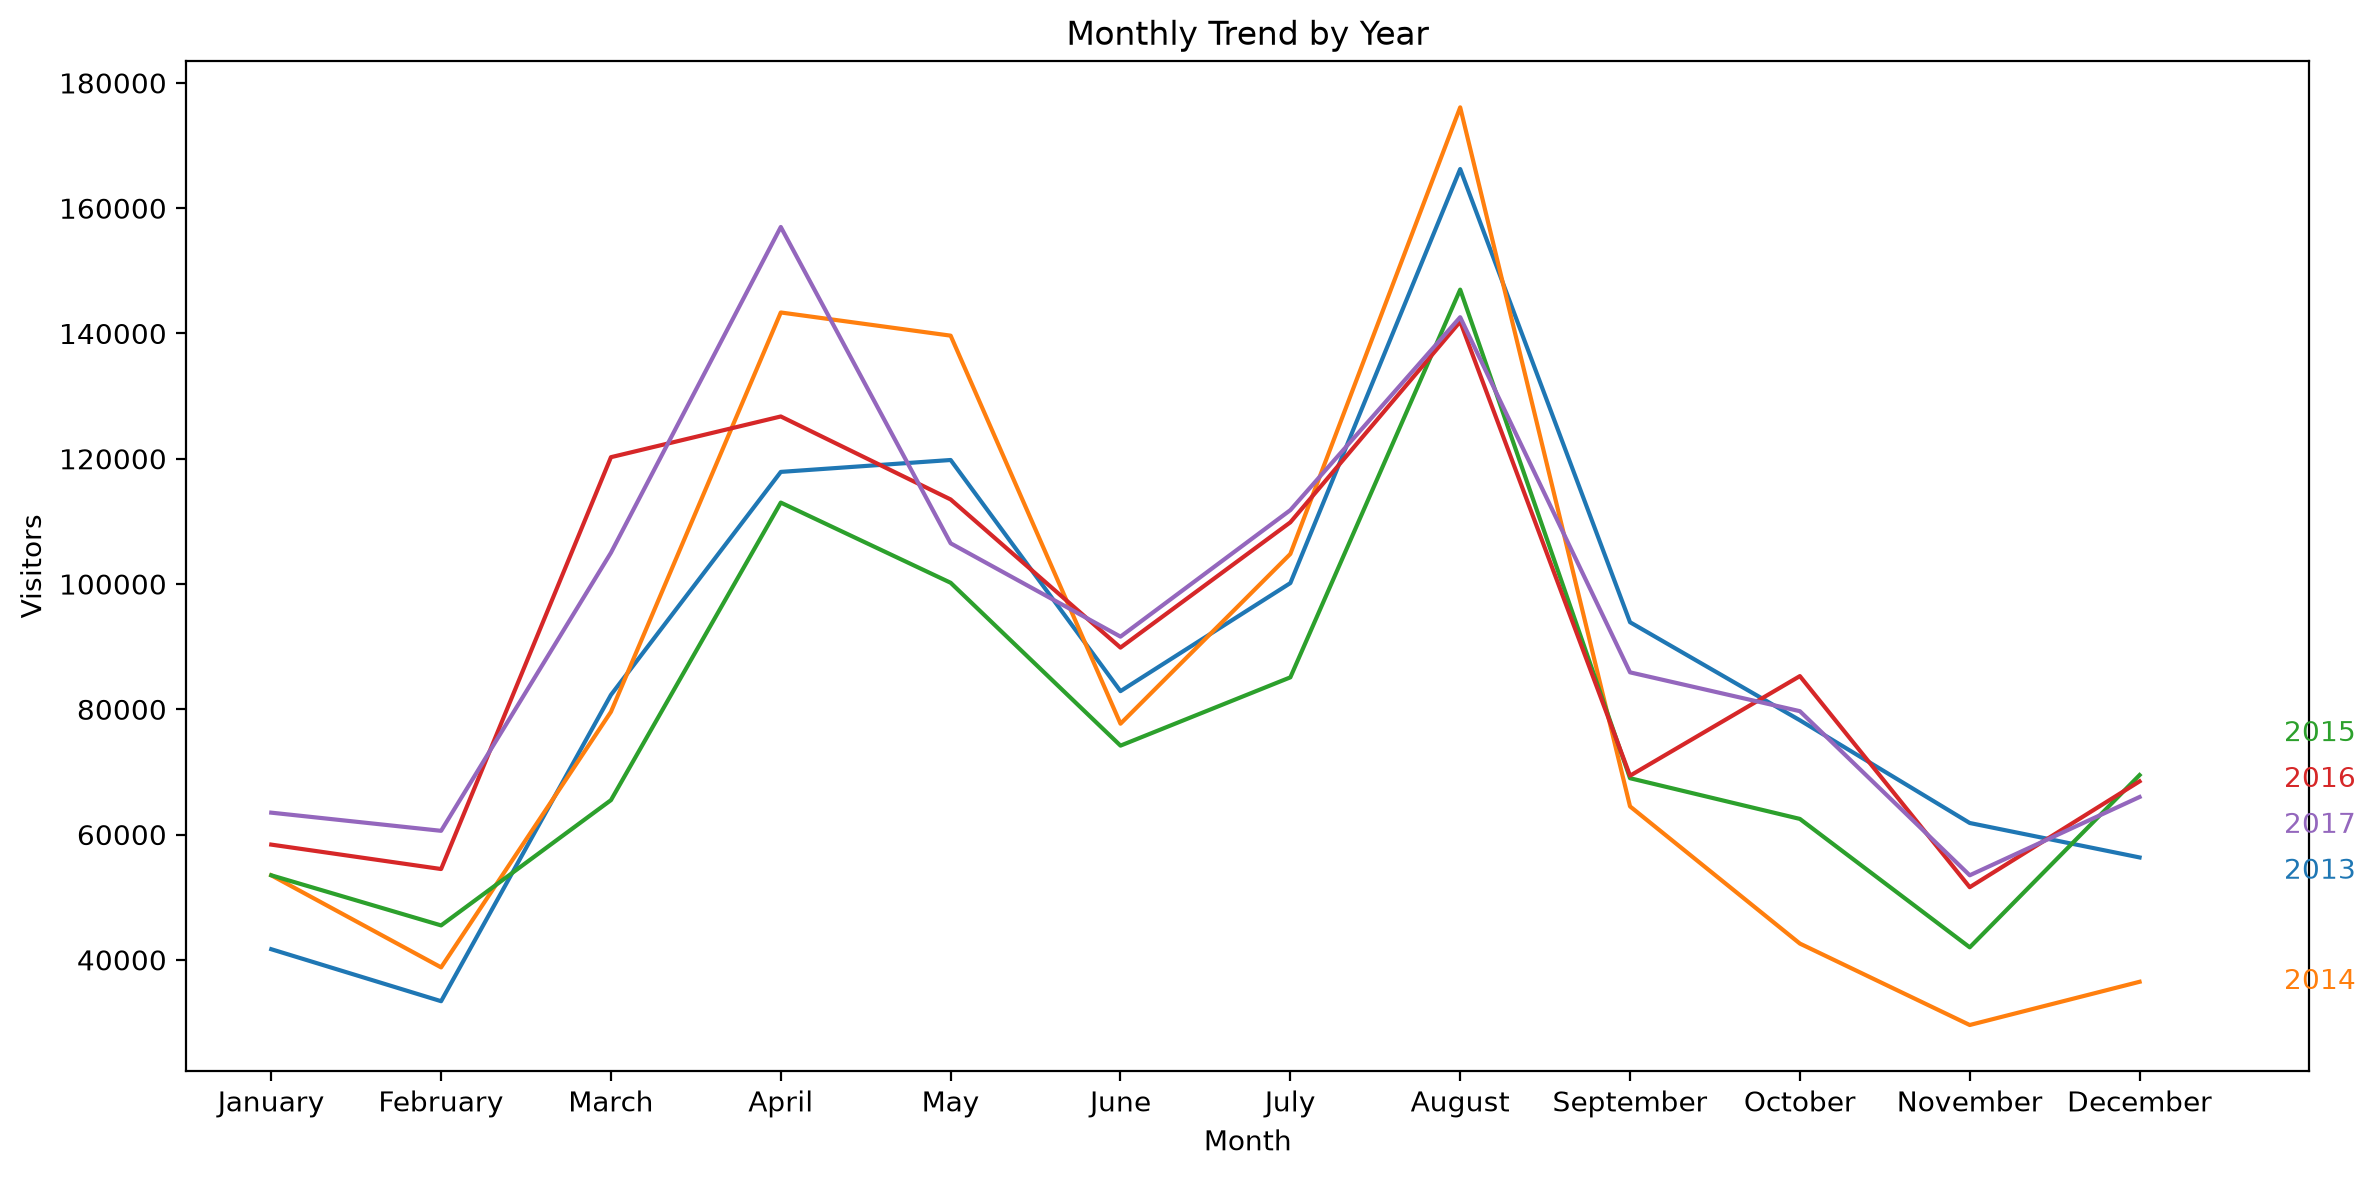

In [ ]:
fig_line, ax_line = plt.subplots(figsize=(12, 6))

line_labels = []
for _year in years:
    _line, = ax_line.plot(df["Mesi"], df[_year])
    line_labels.append(
        {
            "year": _year,
            "y": df[_year].iloc[-1],
            "color": _line.get_color(),
        }
    )

line_labels.sort(key=lambda item: item["y"])
_all_values = [v for _y in years for v in df[_y]]
min_gap = 0.05 * (max(_all_values) - min(_all_values))
# spread overlapping labels apart symmetrically, so each stays near its line end
for _ in range(200):
    _moved = False
    for _i in range(1, len(line_labels)):
        _deficit = min_gap - (line_labels[_i]["y"] - line_labels[_i - 1]["y"])
        if _deficit > 0:
            line_labels[_i]["y"] += _deficit / 2
            line_labels[_i - 1]["y"] -= _deficit / 2
            _moved = True
    if not _moved:
        break

ax_line.set_xlim(-0.5, len(months_en))
for _item in line_labels:
    ax_line.text(
        len(months_en) - 0.15,
        _item["y"],
        _item["year"],
        color=_item["color"],
        va="center",
    )

ax_line.set_title("Monthly Trend by Year")
ax_line.set_xlabel("Month")
ax_line.set_ylabel("Visitors")

fig_line.tight_layout()
fig_line

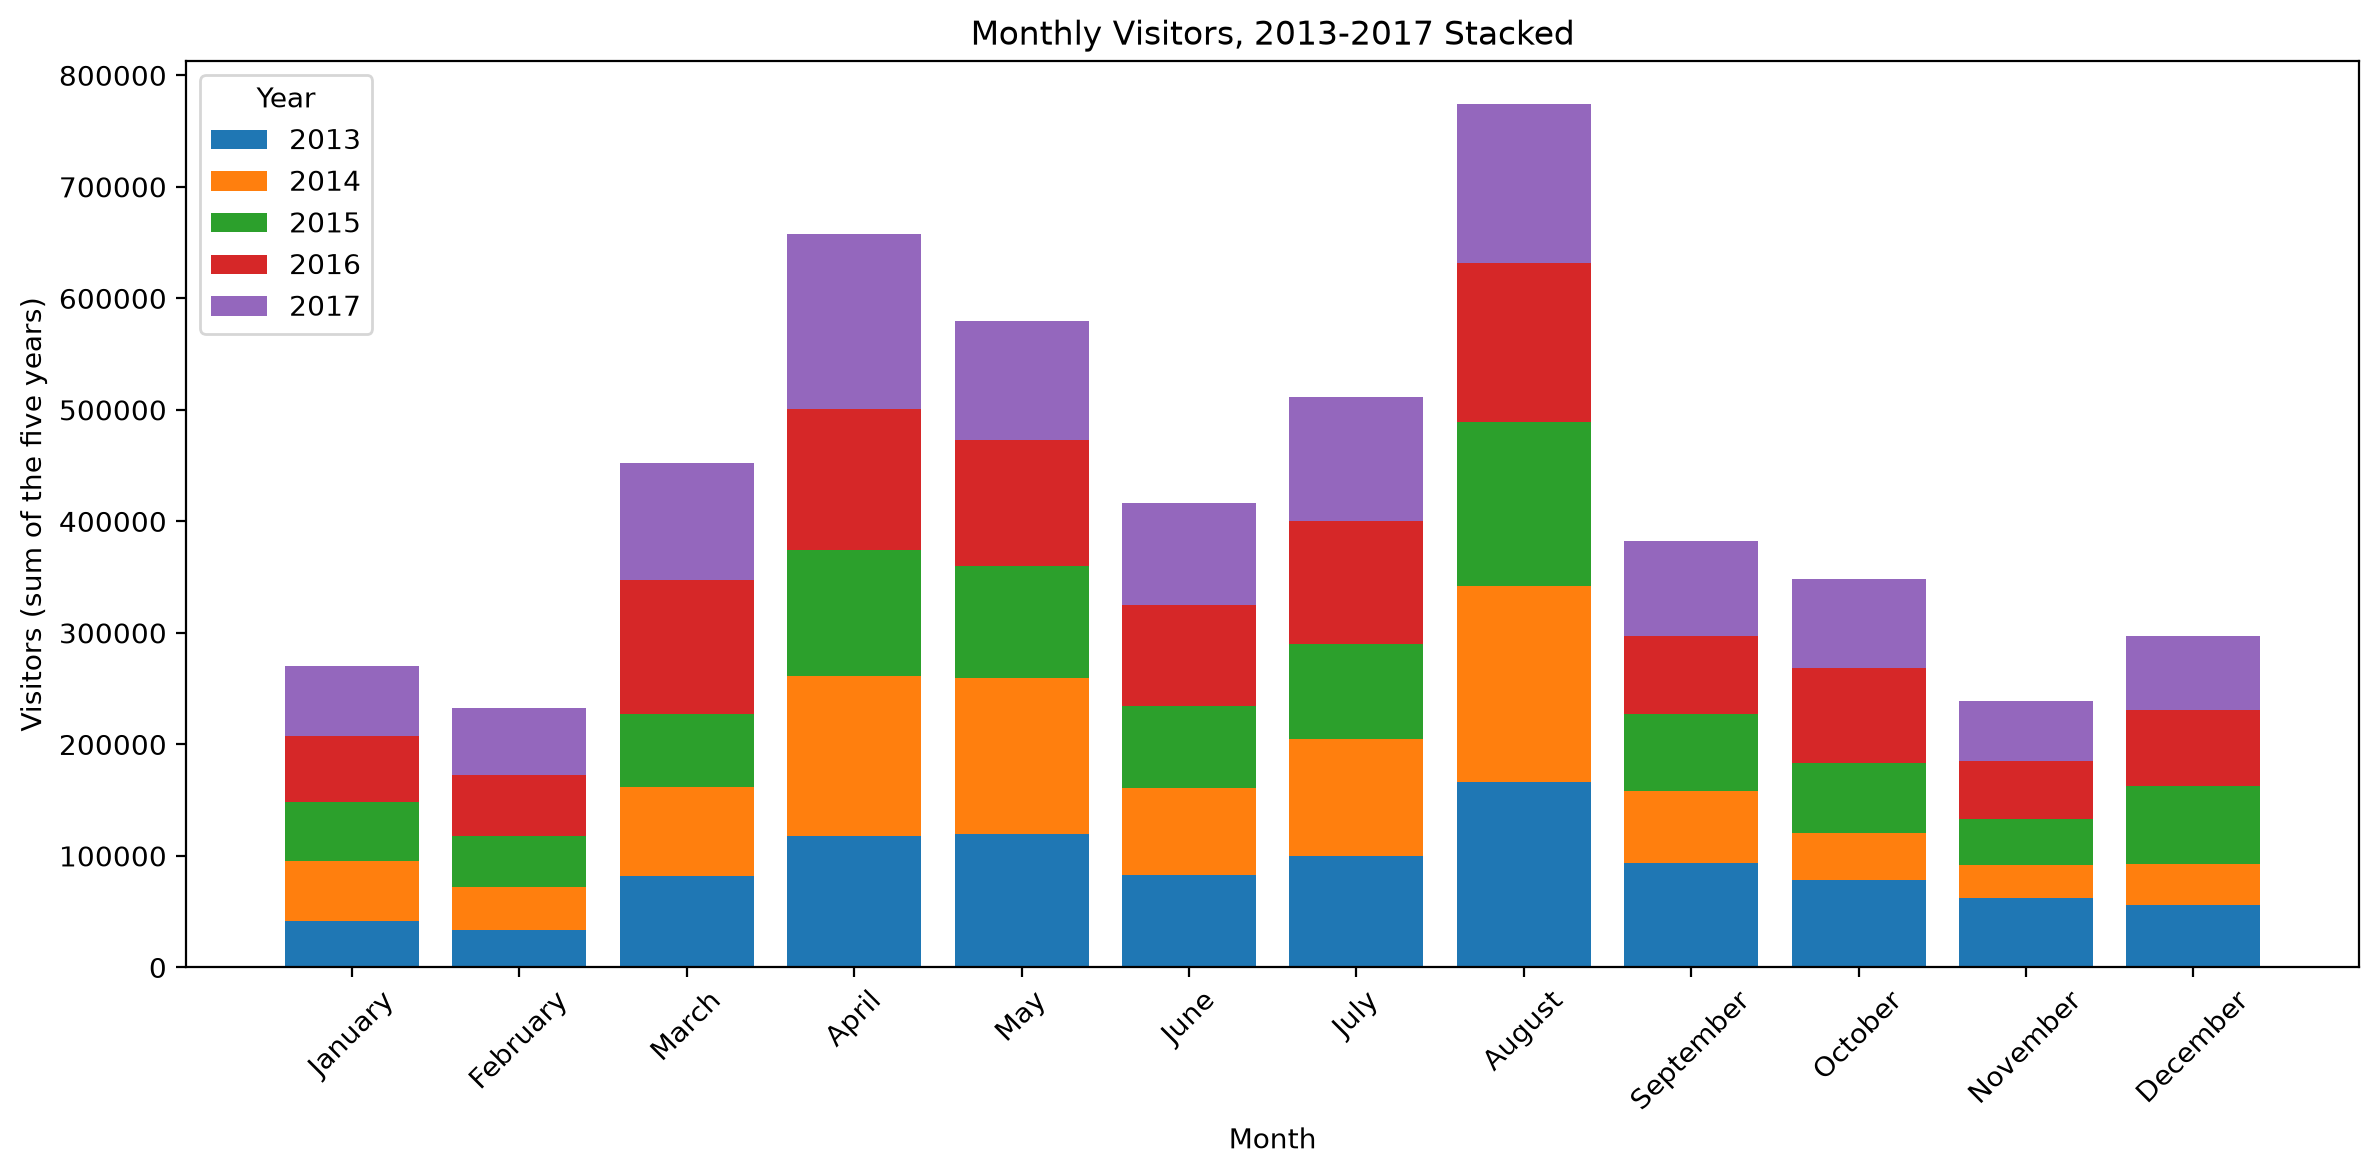

In [ ]:
fig_stack, ax_stack = plt.subplots(figsize=(12, 6))

bottom = [0] * len(df)
for _year in years:
    ax_stack.bar(df["Mesi"], df[_year], bottom=bottom, label=_year)
    bottom = [low + value for low, value in zip(bottom, df[_year])]

ax_stack.set_title("Monthly Visitors, 2013-2017 Stacked")
ax_stack.set_xlabel("Month")
ax_stack.set_ylabel("Visitors (sum of the five years)")
ax_stack.tick_params(axis="x", rotation=45)
ax_stack.legend(title="Year", loc="upper left")

fig_stack.tight_layout()
fig_stack

## Spending breakdown

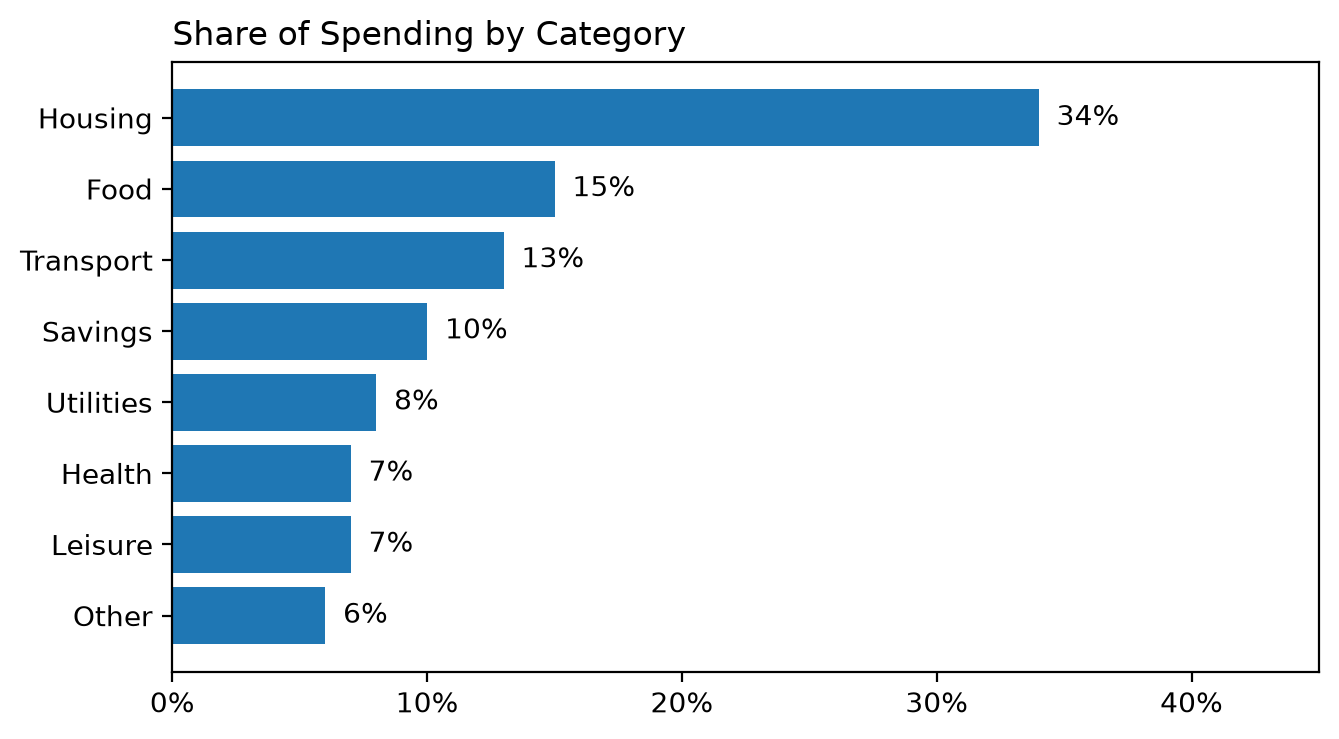

In [ ]:
fig_bar, ax_bar = plt.subplots(figsize=(6.8, 3.8))

categories = [name for name, _ in spend]
shares = np.asarray([value for _, value in spend])
y_bar = np.arange(len(spend))

ax_bar.barh(y_bar, shares)
ax_bar.invert_yaxis()

for y_pos, share in zip(y_bar, shares):
    ax_bar.text(
        share + 0.7,
        y_pos,
        f"{share}%",
        ha="left",
        va="center",
    )

ax_bar.set_xlim(0, 45)
ax_bar.set_xticks([0, 10, 20, 30, 40])
ax_bar.set_xticklabels(["0%", "10%", "20%", "30%", "40%"])
ax_bar.set_yticks(y_bar)
ax_bar.set_yticklabels(categories)
ax_bar.set_title("Share of Spending by Category", loc="left")

fig_bar.tight_layout()
fig_bar

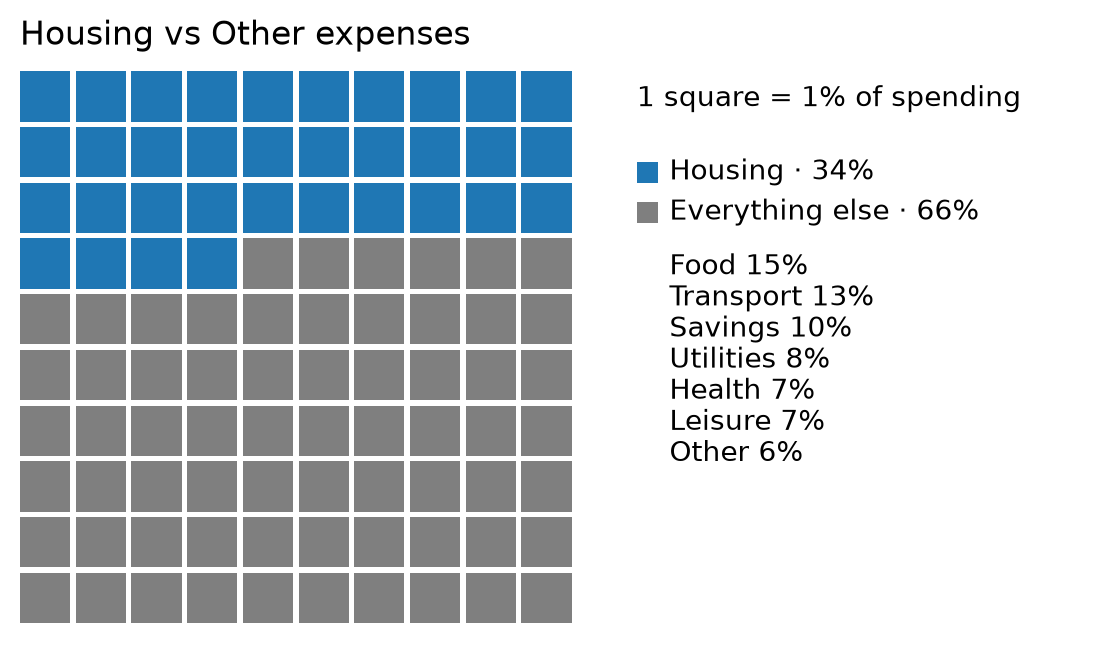

In [ ]:
_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
_housing = _colors[0]
_other = _colors[7]

fig_waf, ax_waf = plt.subplots(figsize=(6.8, 3.8))

cell_fill = []
for cat_idx, (_, value) in enumerate(spend):
    fill = _housing if cat_idx == 0 else _other
    cell_fill.extend([fill] * value)

cell, gap = 1.0, 0.11
grid_total = 10 * cell + 9 * gap
for _idx, fill in enumerate(cell_fill):
    row, col = divmod(_idx, 10)
    x_cell = col * (cell + gap)
    y_cell = row * (cell + gap)
    ax_waf.add_patch(
        plt.Rectangle(
            (x_cell, y_cell),
            cell,
            cell,
            facecolor=fill,
            edgecolor="none",
        )
    )

legend_x = grid_total + 1.3
swatch = 0.42
housing_name, housing_share = spend[0]
rest_share = sum(share for _, share in spend[1:])

ax_waf.text(
    legend_x,
    0.55,
    "1 square = 1% of spending",
    ha="left",
    va="center",
)
legend_y = 1.8
for _swatch_color, _label in (
    (_housing, f"{housing_name} · {housing_share}%"),
    (_other, f"Everything else · {rest_share}%"),
):
    ax_waf.add_patch(
        plt.Rectangle(
            (legend_x, legend_y),
            swatch,
            swatch,
            facecolor=_swatch_color,
            edgecolor="none",
        )
    )
    ax_waf.text(
        legend_x + 0.65,
        legend_y + swatch / 2,
        _label,
        ha="left",
        va="center",
    )
    legend_y += 0.8

legend_y += 0.5
for _name, value in spend[1:]:
    ax_waf.text(
        legend_x + 0.65,
        legend_y,
        f"{_name} {value}%",
        ha="left",
        va="center",
    )
    legend_y += 0.62

ax_waf.set_title("Housing vs Other expenses", loc="left")
ax_waf.set_xlim(0, 21)
ax_waf.set_ylim(grid_total + 0.4, -0.2)
ax_waf.set_aspect("equal")
ax_waf.axis("off")

fig_waf

## Visitors by device

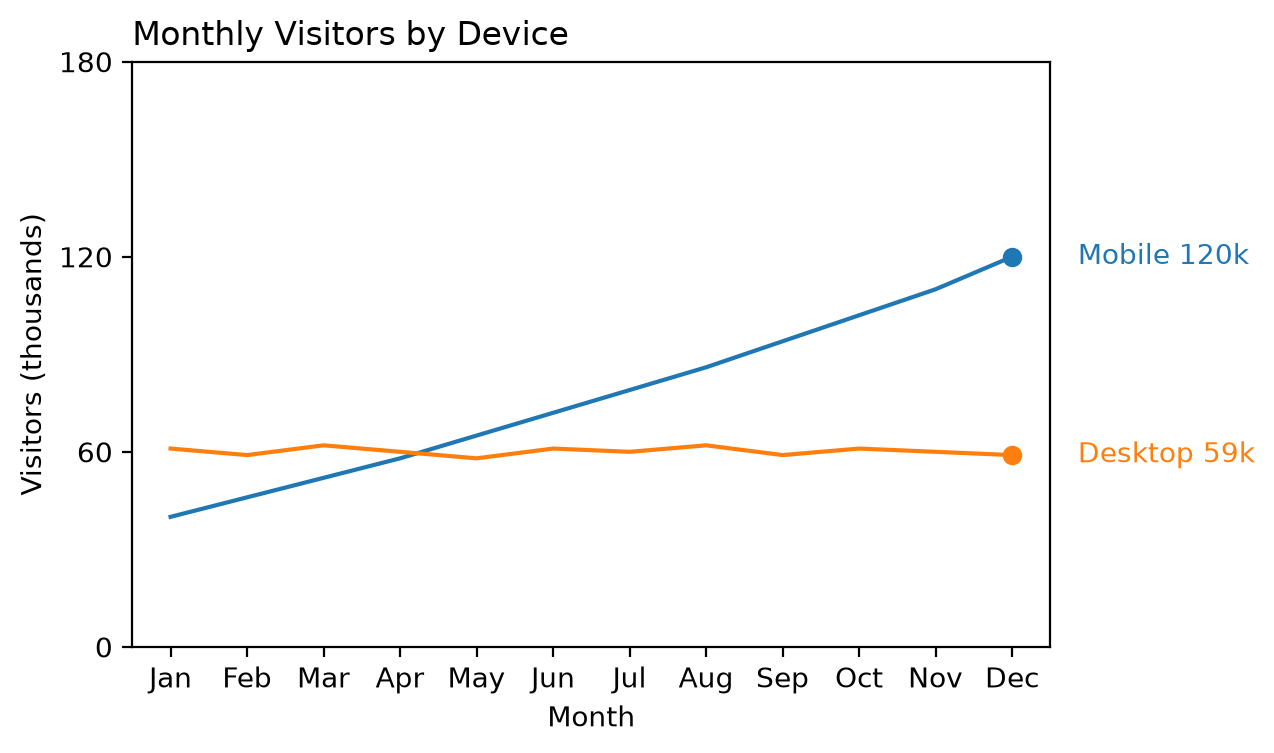

In [ ]:
fig_ml, ax_ml = plt.subplots(figsize=(6.8, 3.8))

x_ml = np.arange(len(months))
mobile_arr_ml = np.asarray(mobile)
desktop_arr_ml = np.asarray(desktop)

for _name, values in (
    ("Mobile", mobile_arr_ml),
    ("Desktop", desktop_arr_ml),
):
    _line, = ax_ml.plot(x_ml, values)  # values are in thousands of visitors
    _color = _line.get_color()
    ax_ml.plot(x_ml[-1], values[-1], linestyle="none", marker="o", color=_color)
    ax_ml.text(
        1.03,
        values[-1],
        f"{_name} {values[-1]}k",
        transform=ax_ml.get_yaxis_transform(),
        ha="left",
        va="center",
        color=_color,
        clip_on=False,
    )

ax_ml.set_xlim(-0.5, len(months) - 0.5)
ax_ml.set_ylim(0, 180)
ax_ml.set_yticks([0, 60, 120, 180])
ax_ml.set_xticks(x_ml)
ax_ml.set_xticklabels(months)
ax_ml.set_title("Monthly Visitors by Device", loc="left")
ax_ml.set_xlabel("Month")
ax_ml.set_ylabel("Visitors (thousands)")

fig_ml.subplots_adjust(right=0.8)
fig_ml

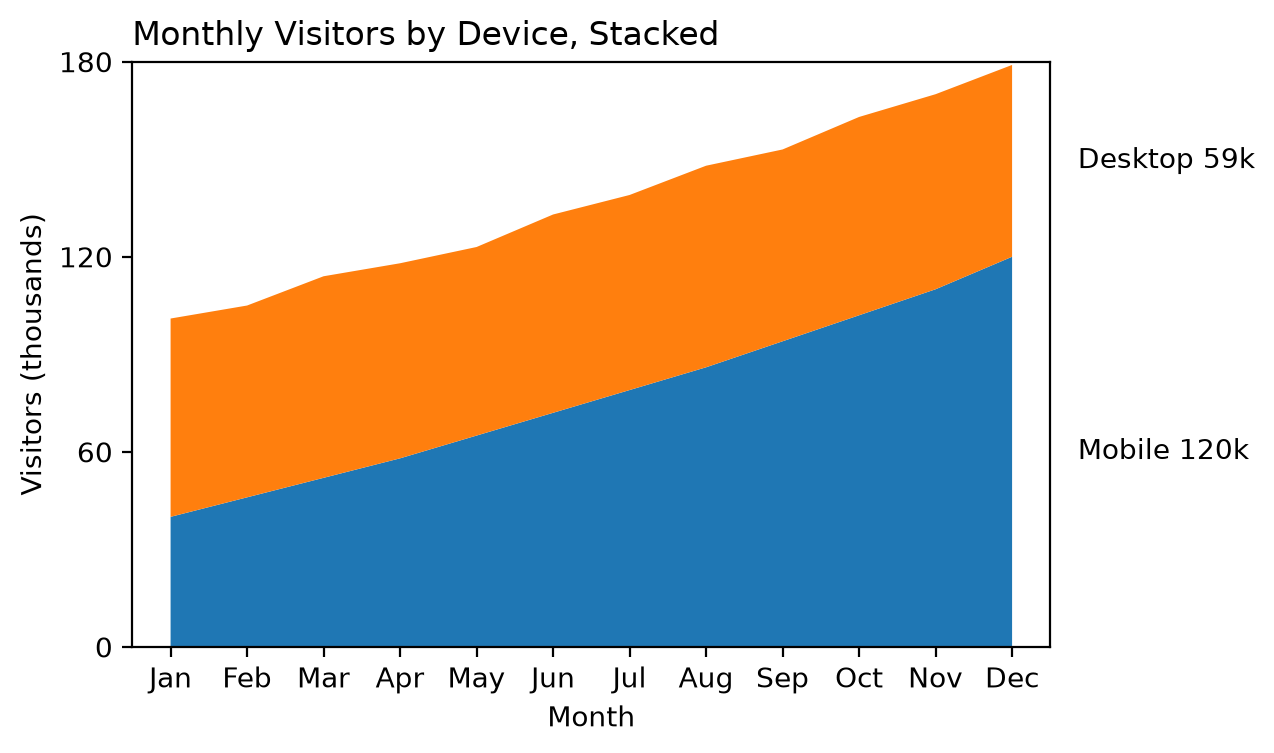

In [ ]:
fig_area, ax_area = plt.subplots(figsize=(6.8, 3.8))

x_area = np.arange(len(months))
mobile_arr = np.asarray(mobile)
desktop_arr = np.asarray(desktop)
total_arr = mobile_arr + desktop_arr

ax_area.fill_between(x_area, 0, mobile_arr)
ax_area.fill_between(x_area, mobile_arr, total_arr)

ax_area.set_xlim(-0.5, len(months) - 0.5)
ax_area.set_ylim(0, 180)
ax_area.set_yticks([0, 60, 120, 180])
ax_area.set_xticks(x_area)
ax_area.set_xticklabels(months)
ax_area.set_title("Monthly Visitors by Device, Stacked", loc="left")
ax_area.set_xlabel("Month")
ax_area.set_ylabel("Visitors (thousands)")

label_x = 1.03
label_transform = ax_area.get_yaxis_transform()
ax_area.text(
    label_x,
    mobile_arr[-1] + desktop_arr[-1] / 2,
    f"Desktop {desktop_arr[-1]}k",
    transform=label_transform,
    ha="left",
    va="center",
    clip_on=False,
)
ax_area.text(
    label_x,
    mobile_arr[-1] / 2,
    f"Mobile {mobile_arr[-1]}k",
    transform=label_transform,
    ha="left",
    va="center",
    clip_on=False,
)

fig_area.subplots_adjust(right=0.8)
fig_area

## Delivery times

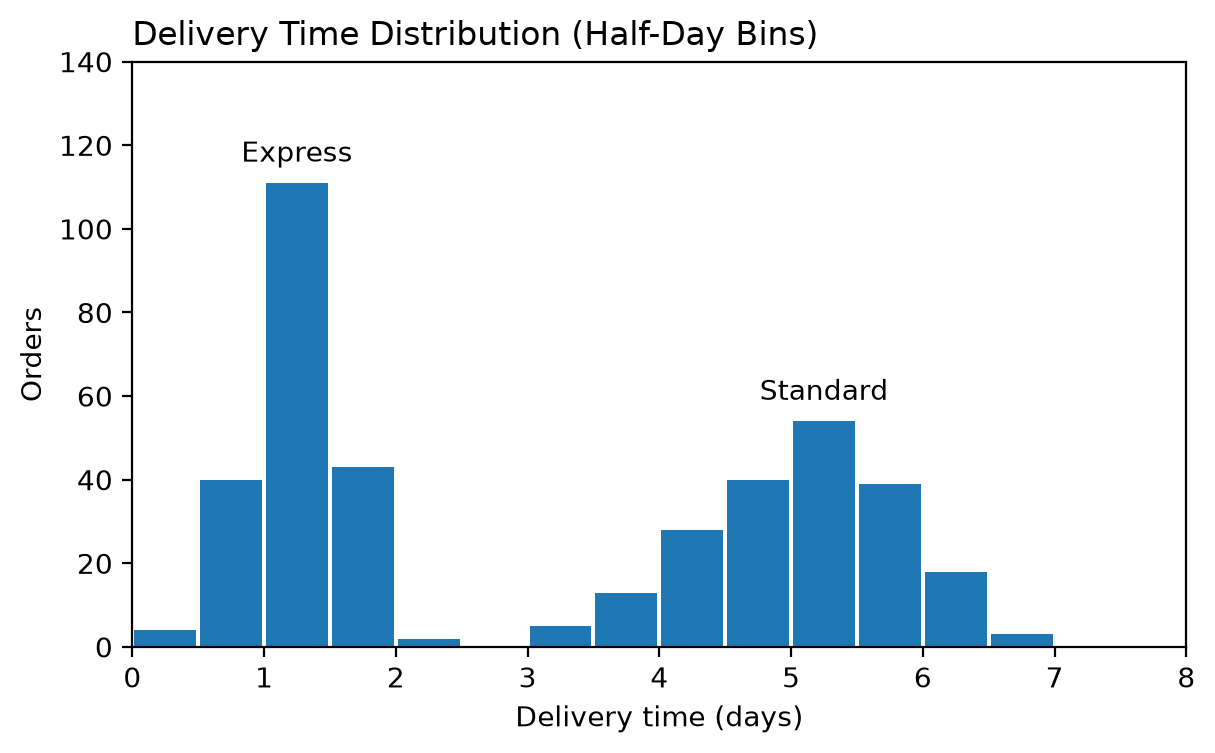

In [ ]:
days = np.asarray(delivery_days)
bin_w = 0.5
edges = np.arange(0, 8 + bin_w, bin_w)
counts, _ = np.histogram(days, bins=edges)
# round up with ~10% headroom so the bar labels always fit inside the axis
top = int(np.ceil(counts.max() * 1.1 / 20) * 20)

fig_hist, ax_hist = plt.subplots(figsize=(6.8, 3.8))

centers = edges[:-1] + bin_w / 2
ax_hist.bar(
    centers,
    counts,
    width=bin_w - 0.03,
)

ax_hist.set_xlim(0, 8)
ax_hist.set_ylim(0, top)
ax_hist.set_xticks(np.arange(0, 9))
ax_hist.set_yticks(np.arange(0, top + 1, 20))
ax_hist.set_title("Delivery Time Distribution (Half-Day Bins)", loc="left")
ax_hist.set_xlabel("Delivery time (days)")
ax_hist.set_ylabel("Orders")

express_bin = int(np.argmax(np.where(edges[:-1] < 3, counts, -1)))
standard_bin = int(
    np.argmax(np.where((edges[:-1] >= 3) & (edges[:-1] < 8), counts, -1))
)
for _name, _idx in (("Express", express_bin), ("Standard", standard_bin)):
    ax_hist.text(
        centers[_idx],
        counts[_idx] + top * 0.025,
        _name,
        ha="center",
        va="bottom",
    )

fig_hist

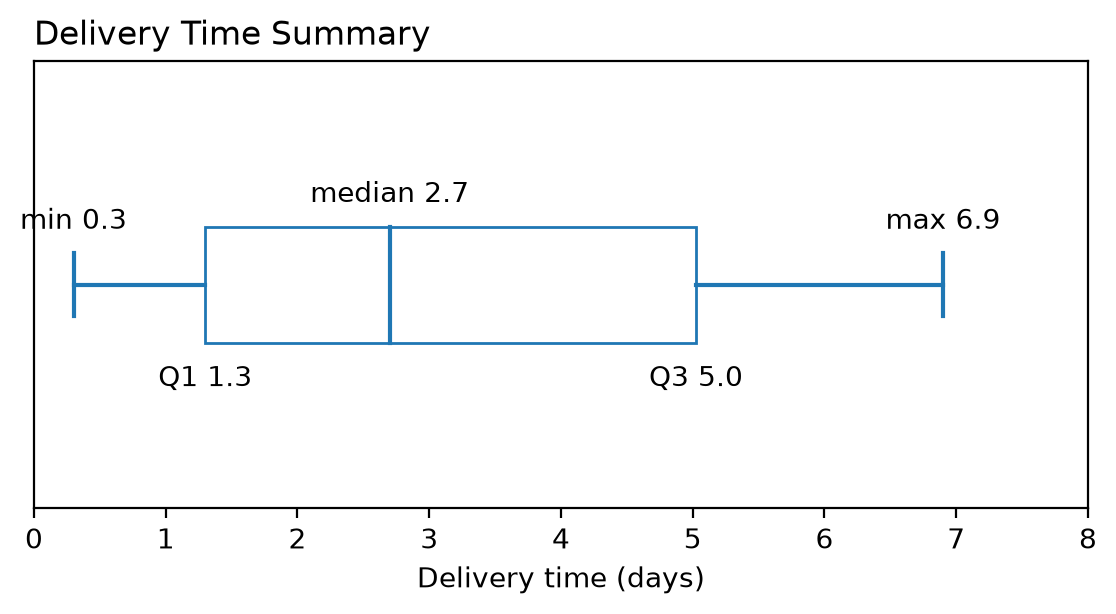

In [ ]:
days_sorted = np.sort(np.asarray(delivery_days))
q1, median, q3 = np.percentile(days_sorted, [25, 50, 75])
iqr = q3 - q1
whisker_lo = days_sorted[days_sorted >= q1 - 1.5 * iqr][0]
whisker_hi = days_sorted[days_sorted <= q3 + 1.5 * iqr][-1]

fig_box, ax_box = plt.subplots(figsize=(6.8, 2.9))

ax_box.set_xlim(0, 8)
ax_box.set_ylim(0, 1)
ax_box.set_xticks(np.arange(0, 9))
ax_box.set_yticks([])
ax_box.set_title("Delivery Time Summary", loc="left")
ax_box.set_xlabel("Delivery time (days)")

cy, box_h = 0.5, 0.26
_color = plt.rcParams["axes.prop_cycle"].by_key()["color"][0]

ax_box.plot([whisker_lo, q1], [cy, cy], color=_color)
ax_box.plot([q3, whisker_hi], [cy, cy], color=_color)
for whisker in (whisker_lo, whisker_hi):
    ax_box.plot(
        [whisker, whisker],
        [cy - 0.07, cy + 0.07],
        color=_color,
    )

ax_box.add_patch(
    plt.Rectangle(
        (q1, cy - box_h / 2),
        q3 - q1,
        box_h,
        facecolor="none",
        edgecolor=_color,
    )
)
ax_box.plot(
    [median, median],
    [cy - box_h / 2, cy + box_h / 2],
    color=_color,
)

ax_box.text(
    median,
    cy + box_h / 2 + 0.04,
    f"median {median:.1f}",
    ha="center",
    va="bottom",
)
ax_box.text(
    q1,
    cy - box_h / 2 - 0.05,
    f"Q1 {q1:.1f}",
    ha="center",
    va="top",
)
ax_box.text(
    q3,
    cy - box_h / 2 - 0.05,
    f"Q3 {q3:.1f}",
    ha="center",
    va="top",
)
ax_box.text(
    whisker_lo,
    cy + 0.11,
    f"min {whisker_lo:.1f}",
    ha="center",
    va="bottom",
)
ax_box.text(
    whisker_hi,
    cy + 0.11,
    f"max {whisker_hi:.1f}",
    ha="center",
    va="bottom",
)

fig_box